# 07 - Dual upper bound: how far is the LSMC policy from optimal?

LSMC on independent paths gives a **lower bound**: the value of a feasible but sub-optimal policy. A dual
(information-relaxation) bound gives an **upper bound** (Rogers, 2002; Haugh & Kogan, 2004; Andersen & Broadie, 2004;
Brown, Smith & Sun, 2010): let the operator see the whole price path, but charge a penalty with zero conditional mean
for every decision, then solve a deterministic dynamic programme on each path.

$$V^* \le \mathbb E\Big[\max_{v_1..v_K}\sum_k\big(\pi_k(v_k\to v_{k+1};S_{t_k}) - p_k(v_{k+1})\big)\Big],\qquad
p_k(v') = \big(\phi(X_{t_{k+1}}) - \mathbb E_k[\phi(X_{t_{k+1}})]\big)^\top\hat\gamma_{k+1}(v').$$

$\hat\gamma$ regresses the realised values on the basis in the LSMC backward pass. With the polynomial basis and the
Gaussian transition of $X$, $\mathbb E_k[\phi(X_{t_{k+1}})]$ is analytic, so no nested simulation is needed.

**Which problem is bounded.** A bound needs one well-defined problem. Here it is the *grid-restricted* storage:
inventory on the volume grid and moves between grid levels within the rate limits. Its LSMC policy (`moves="grid"`)
gives the lower bound and the dual gives the upper bound; the headline LSMC of notebook 04 also allows full-rate moves
off the grid, so it is a slightly larger problem and is shown for comparison. The grid step must be finer than the
smallest ratcheted move (35 GWh per week of withdrawal below 30 % fill), otherwise the grid-restricted storage could
not be emptied.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")

from gasstorage import plotting
from gasstorage.config import load_config
from gasstorage.models.one_factor import OneFactorModel
from gasstorage.storage.contract import build_inputs
from gasstorage.storage.dual import dual_upper_bound
from gasstorage.storage.lsmc import lsmc_value

plotting.apply_style()
N = 10_000
cases = {
    "market (EEX)": "configs/storage_default.yaml",
    "contango (SYNTHETIC)": "configs/storage_synthetic.yaml",
}
params = {
    "1F, P (kappa 4.78)": OneFactorModel(4.784, 0.694),
    "1F, Q (kappa 0.33)": OneFactorModel(0.326, 0.694),
}
runs = [("1F, P (kappa 4.78)", 101), ("1F, P (kappa 4.78)", 201), ("1F, Q (kappa 0.33)", 101)]

In [2]:
rows = []
for case, path in cases.items():
    inp = build_inputs(load_config(path), "weekly")
    for pname, levels in runs:
        model = params[pname]
        t0 = time.perf_counter()
        lb = lsmc_value(
            inp,
            model,
            N,
            N,
            np.random.default_rng(12345),
            np.random.default_rng(67890),
            n_levels=levels,
            moves="grid",
        )
        ub = dual_upper_bound(inp, model, lb.policy, N, np.random.default_rng(24680))
        headline = lsmc_value(
            inp,
            model,
            N,
            N,
            np.random.default_rng(12345),
            np.random.default_rng(67890),
            n_levels=levels,
        )
        finite = ub.penalty_se > 0
        rows.append(
            {
                "case": case,
                "parameters": pname,
                "grid": levels,
                "lower bound": lb.value / 1e6,
                "LB SE": lb.se / 1e6,
                "upper bound": ub.value / 1e6,
                "UB SE": ub.se / 1e6,
                "gap": (ub.value - lb.value) / 1e6,
                "gap % of LB": 100 * (ub.value - lb.value) / lb.value if lb.value > 0 else np.nan,
                "LSMC with off-grid moves": headline.value / 1e6,
                "penalties within 3 SE of 0 (%)": 100
                * np.mean(np.abs(ub.mean_penalty[finite]) < 3 * ub.penalty_se[finite]),
                "time (s)": time.perf_counter() - t0,
            }
        )
bounds = pd.DataFrame(rows).set_index(["case", "parameters", "grid"])
print("MEUR, discounted to 2026-11-17; grid-restricted problem unless stated")
bounds.round(3)

MEUR, discounted to 2026-11-17; grid-restricted problem unless stated


lower bound  LB SE  upper bound  \
case                 parameters         grid                                    
market (EEX)         1F, P (kappa 4.78) 101         4.378  0.053        4.496   
                                        201         4.875  0.057        5.003   
                     1F, Q (kappa 0.33) 101        -0.135  0.025        0.162   
contango (SYNTHETIC) 1F, P (kappa 4.78) 101         7.332  0.051        7.439   
                                        201         8.006  0.055        8.122   
                     1F, Q (kappa 0.33) 101         5.961  0.138        5.996   

                                              UB SE    gap  gap % of LB  \
case                 parameters         grid                              
market (EEX)         1F, P (kappa 4.78) 101   0.018  0.118        2.707   
                                        201   0.020  0.128        2.616   
                     1F, Q (kappa 0.33) 101   0.009  0.297          NaN   
contango (SYNTHETIC) 1F, P (kappa 4.78) 101   0.013  0.107        1.458   
                                        201   0.014  0.116        1.455   
                     1F, Q (kappa 0.33) 101   0.013  0.034        0.576   

                                              LSMC with off-grid moves  \
case                 parameters         grid                             
market (EEX)         1F, P (kappa 4.78) 101                      4.895   
                                        201                      4.986   
                     1F, Q (kappa 0.33) 101                     -0.134   
contango (SYNTHETIC) 1F, P (kappa 4.78) 101                      7.980   
                                        201                      8.163   
                     1F, Q (kappa 0.33) 101                      6.546   

                                              penalties within 3 SE of 0 (%)  \
case                 parameters         grid                                   
market (EEX)         1F, P (kappa 4.78) 101                            100.0   
                                        201                            100.0   
                     1F, Q (kappa 0.33) 101                            100.0   
contango (SYNTHETIC) 1F, P (kappa 4.78) 101                            100.0   
                                        201                            100.0   
                     1F, Q (kappa 0.33) 101                            100.0   

                                              time (s)  
case                 parameters         grid            
market (EEX)         1F, P (kappa 4.78) 101     62.640  
                                        201    211.584  
                     1F, Q (kappa 0.33) 101     61.454  
contango (SYNTHETIC) 1F, P (kappa 4.78) 101     58.443  
                                        201    190.567  
                     1F, Q (kappa 0.33) 101     59.330

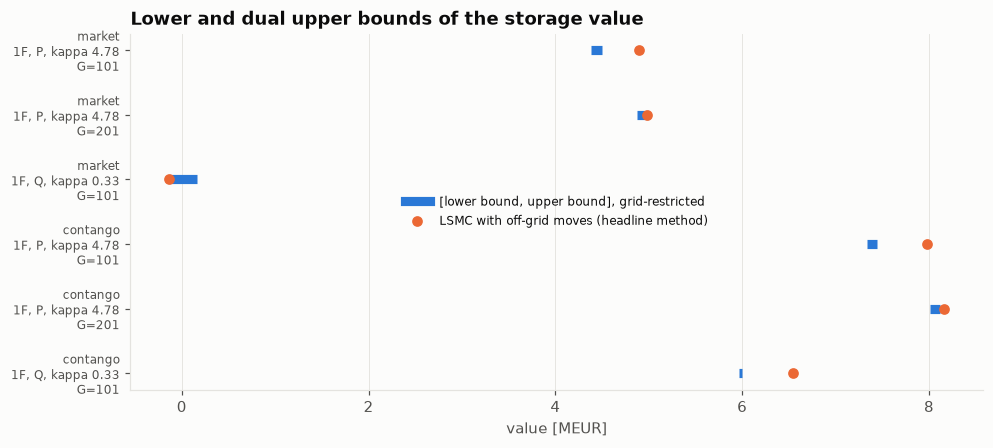

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
labels = [
    f"{c.split(' ')[0]}\n{p.split(' (')[0]}, {p.split('(')[1][:-1]}\nG={g}"
    for c, p, g in bounds.index
]
y = np.arange(len(bounds))
for yi, (_, r) in zip(y, bounds.iterrows(), strict=True):
    ax.plot(
        [r["lower bound"], r["upper bound"]],
        [yi, yi],
        color=plotting.SERIES[0],
        lw=6,
        solid_capstyle="butt",
    )
    ax.plot(r["LSMC with off-grid moves"], yi, "o", color=plotting.SERIES[1], ms=6)
ax.plot([], [], color=plotting.SERIES[0], lw=6, label="[lower bound, upper bound], grid-restricted")
ax.plot([], [], "o", color=plotting.SERIES[1], label="LSMC with off-grid moves (headline method)")
ax.set_yticks(y, labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("value [MEUR]")
ax.set_title("Lower and dual upper bounds of the storage value")
ax.legend(loc="center", fontsize=8)
ax.grid(axis="y", visible=False)
plotting.save_figure(fig, "07_dual_bounds")
fig

## Findings

| MEUR (grid-restricted problem) | lower bound | upper bound | gap |
|---|---|---|---|
| market, 1F $\mathbb P$, 101 levels | 4.378 (0.053) | 4.496 (0.018) | 2.7 % |
| market, 1F $\mathbb P$, 201 levels | 4.875 (0.057) | 5.003 (0.020) | 2.6 % |
| market, 1F $\mathbb Q$ ($\kappa$ 0.33), 101 levels | -0.135 (0.025) | 0.162 (0.009) | optimum in [0, 0.16] |
| contango, 1F $\mathbb P$, 101 levels | 7.332 (0.051) | 7.439 (0.013) | 1.5 % |
| contango, 1F $\mathbb P$, 201 levels | 8.006 (0.055) | 8.122 (0.014) | 1.5 % |
| contango, 1F $\mathbb Q$, 101 levels | 5.961 (0.138) | 5.996 (0.013) | 0.6 % |

* **The LSMC policy is near-optimal.** Under the reference parameters the duality gap is 1.5-2.7 % of the value, so
  the headline numbers are not an artefact of a poor regression: the true optimum of the grid-restricted problem lies
  within about 0.1 MEUR of the LSMC value.
* **The risk-neutral value is small, and now provably so.** Under the one-factor $\mathbb Q$ dynamics the market-case
  storage is worth at most 0.16 MEUR whatever the policy (and at least 0, since doing nothing is feasible), against
  about 4.9 MEUR under the historical dynamics. The negative LSMC estimate is a weak policy, not a negative value.
* **Penalties behave as martingale increments:** every per-step, per-level average penalty is within three standard
  errors of zero.
* **Grid-restricted vs headline problem.** The headline LSMC also allows full-rate moves off the grid, a slightly
  larger action set; at 101 levels it is therefore above the grid-restricted upper bound (4.90 vs 4.50). As the grid
  is refined the two problems converge (4.99 vs [4.88, 5.00] at 201 levels).
* The bound costs about one LSMC run: the conditional expectations of the polynomial basis are analytic under the
  Gaussian transition, so no nested simulation is needed.